Libraries loaded. Initializing external validation pipeline...
****************************************************************************************************
✓ GPU allocation locked for evaluation graph.

[Data Ingestion] Parsing External Dataset (Kvasir-SEG) Paths...
Total external paired samples found: 612

🔄 Loading trained weight-state model from: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras
✅ Model layers graph initialized cleanly.

⏱️ Evaluating model performance across external domain dataset...


I0000 00:00:1783003176.266073   11556 service.cc:153] XLA service 0x75068405f430 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1783003176.266121   11556 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 12.7.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1783003176.633193   11556 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1783003177.390524   11556 cuda_dnn.cc:461] Loaded cuDNN version 92101
E0000 00:00:1783003181.470915   11556 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E0000 00:00:1783003185.041874   11556 cuda_timer.cc:87] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
E

153/153 ━━━━━━━━━━━━━━━━━━━━ 40s 61ms/step - loss: 0.3275 - seg_output_accuracy: 0.9617 - seg_output_dice_coef: 0.7621 - seg_output_f2_segmentation: 0.7559 - seg_output_iou_metric: 0.6464 - seg_output_mean_iou_metric: 0.6464 - seg_output_precision_segmentation: 0.8316 - seg_output_recall: 0.7309 - seg_output_tnr_metric: 0.9847

               EXTERNAL VALIDATION METRICS REPORT                
 • loss                                    : 0.3275

🔮 Generating sample localized visual segmentation maps...


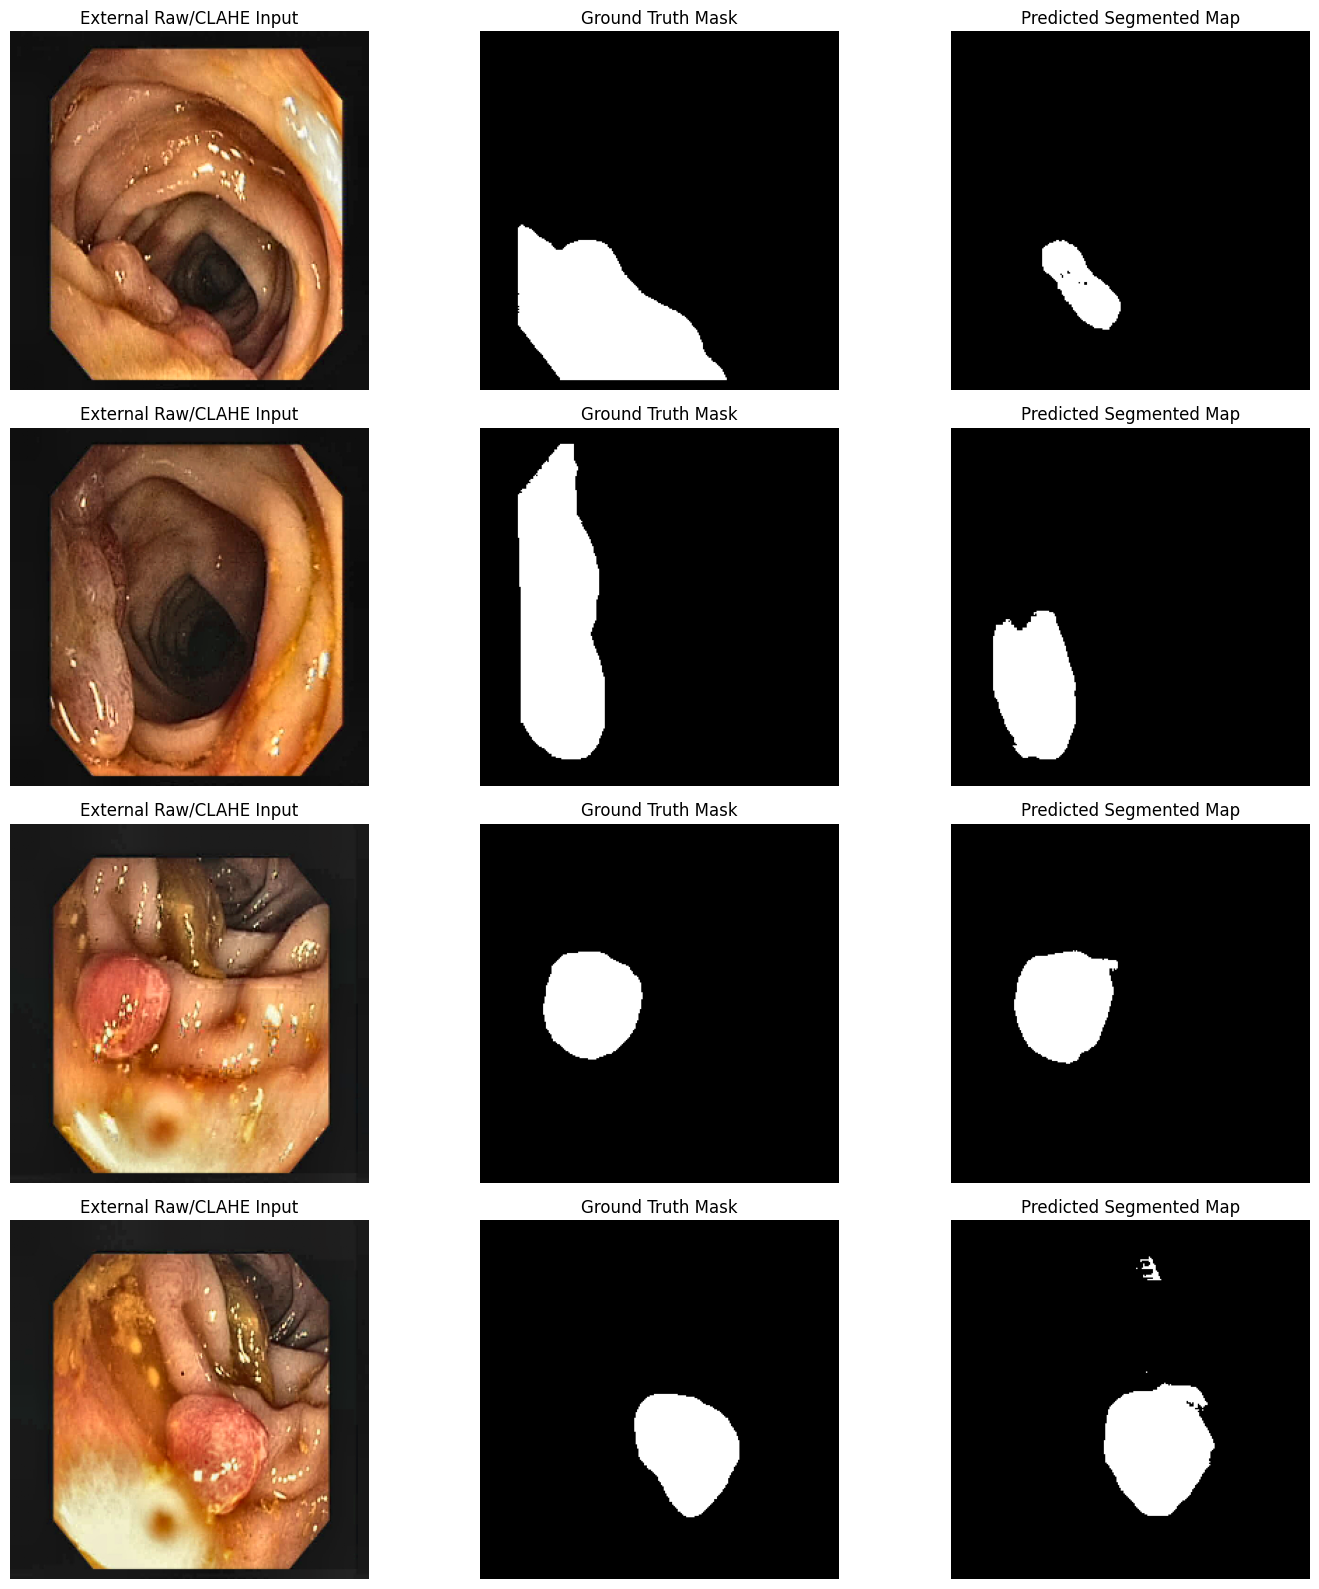

In [3]:
import os
import glob
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import keras
from tensorflow.keras import layers

# --- GLOBAL CONFIGURATION FOR EXTERNAL VALIDATION ---
IMG_SIZE = 256
BATCH_SIZE = 4
EXTERNAL_DATA_PATH = '/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/CVC-ClinicDB/PNG'
# Path to your saved trained model (.keras file)
SAVED_MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"


print("Libraries loaded. Initializing external validation pipeline...")
print("*" * 100)

# --- PHYSICAL HARDWARE CONFIGURATION ---
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus: 
            tf.config.experimental.set_memory_growth(gpu, True)
        print("✓ GPU allocation locked for evaluation graph.")
    except RuntimeError as e: 
        print(e)
@keras.saving.register_keras_serializable()
def precision_segmentation(y_true, y_pred):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    
    return (tp + 1e-6) / (tp + fp + 1e-6)

# --- CUSTOM LAYERS & MODEL ARTIFACT REGISTERING ---
@tf.keras.utils.register_keras_serializable()
class KerasPCCLayer(layers.Layer):
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)

    def call(self, inputs):
        epsilon = 1e-8
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1))
        return layers.Flatten()(pcc_matrix)


# --- REUSED EXACT METRICS & CUSTOM FUNCTIONS FROM TRAINING CODE ---
@keras.saving.register_keras_serializable()
def dice_coef(y_true, y_pred, smooth=1.0):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.clip_by_value(tf.cast(tf.reshape(y_pred, [-1]), tf.float32), 1e-7, 1.0 - 1e-7)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

@keras.saving.register_keras_serializable()
def focal_tversky_loss(y_true, y_pred, alpha=0.7, beta=0.3, gamma=0.75):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.clip_by_value(tf.cast(tf.reshape(y_pred, [-1]), tf.float32), 1e-7, 1.0 - 1e-7)
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    smooth = 1e-6
    tversky_index = (tp + smooth) / (tp + alpha * fn + beta * fp + smooth)
    loss_val = tf.math.pow(tf.clip_by_value(1.0 - tversky_index, 1e-7, 1.0), gamma)
    return loss_val

@keras.saving.register_keras_serializable()
def iou_metric(y_true, y_pred):
    y_true_f = tf.cast(y_true, tf.float32)
    y_pred_f = tf.cast(y_pred > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + 1.0) / (union + 1.0)

# Added missing target dictionary component to intercept saved topology configuration
@keras.saving.register_keras_serializable()
def mean_iou_metric(y_true, y_pred):
    y_true_f = tf.cast(y_true, tf.float32)
    y_pred_f = tf.cast(y_pred > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + 1.0) / (union + 1.0)

@keras.saving.register_keras_serializable()
def tnr_metric(y_true, y_pred):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.clip_by_value(tf.cast(tf.reshape(y_pred, [-1]), tf.float32), 1e-7, 1.0 - 1e-7)
    true_negatives = tf.reduce_sum(tf.cast((1.0 - y_true_f) * (1.0 - y_pred_f), tf.float32))
    false_positives = tf.reduce_sum(tf.cast((1.0 - y_true_f) * y_pred_f, tf.float32))
    return (true_negatives + 1e-6) / (true_negatives + false_positives + 1e-6)

@keras.saving.register_keras_serializable()
def f2_segmentation(y_true, y_pred):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))
    return (5.0 * tp + 1e-6) / (5.0 * tp + 4.0 * fn + fp + 1e-6)


# --- REUSED ORIGINAL PIPELINE FUNCTIONS ---
def process_path_segmentation(img_path, mask_path):
    def _read_and_process(img_p, mask_p):
        img_p_str = img_p.numpy().decode('utf-8') if hasattr(img_p, 'numpy') else img_p.decode('utf-8')
        mask_p_str = mask_p.numpy().decode('utf-8') if hasattr(mask_p, 'numpy') else mask_p.decode('utf-8')
        
        img = cv2.imread(img_p_str)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        
        mask = cv2.imread(mask_p_str, cv2.IMREAD_GRAYSCALE)
        mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE))
        
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        l_channel, a_channel, b_channel = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        cl = clahe.apply(l_channel)
        limg = cv2.merge((cl, a_channel, b_channel))
        enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
        
        median_blur = cv2.medianBlur(enhanced_img, 3) 
        sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)
        
        normalized_img = sharpened / 255.0
        normalized_mask = mask / 255.0
        normalized_mask = np.where(normalized_mask > 0.5, 1.0, 0.0)
        normalized_mask = np.expand_dims(normalized_mask, axis=-1)
        
        clf_label = np.array([1.0], dtype=np.float32)
        return (normalized_img.astype(np.float32), 
                normalized_mask.astype(np.float32), 
                clf_label)

    [img_tensor, mask_tensor, clf_tensor] = tf.py_function(
        _read_and_process, 
        [img_path, mask_path], 
        [tf.float32, tf.float32, tf.float32]
    )
    img_tensor.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask_tensor.set_shape([IMG_SIZE, IMG_SIZE, 1])
    clf_tensor.set_shape([1])
    return img_tensor, mask_tensor, clf_tensor

def load_segmentation_paths(base_path):
    all_images, all_masks = [], []
    img_dir = os.path.join(base_path, "images")
    mask_dir = os.path.join(base_path, "masks")
    
    if os.path.exists(img_dir) and os.path.exists(mask_dir):
        img_paths = []
        for ext in ("*.jpg", "*.JPG", "*.png", "*.PNG", "*.jpeg", "*.JPEG"):
            img_paths.extend(glob.glob(os.path.join(img_dir, ext)))
            
        for img_p in img_paths:
            filename = os.path.basename(img_p)
            mask_p = os.path.join(mask_dir, filename)
            if os.path.exists(mask_p):
                all_images.append(img_p)
                all_masks.append(mask_p)
    else:
        print(f"Error: Target directories not found in root path: {base_path}")
    print(f"Total external paired samples found: {len(all_images)}")
    return all_images, all_masks

def map_tuple_to_model_outputs(*args):
    if len(args) == 1:
        args = args[0]
    image, mask, clf_label = args
    return image, {
        'seg_output': mask,
        'ds1_output': mask,
        'ds2_output': mask,
        'ds3_output': mask,
        'clf_output': clf_label
    }

# --- STEP 1: LOADING EXTERNAL VALIDATION DATASET ---
print("\n[Data Ingestion] Parsing External Dataset (Kvasir-SEG) Paths...")
ext_imgs, ext_masks = load_segmentation_paths(EXTERNAL_DATA_PATH)

external_val_ds = tf.data.Dataset.from_tensor_slices((ext_imgs, ext_masks)) \
    .map(process_path_segmentation, num_parallel_calls=tf.data.AUTOTUNE) \
    .map(map_tuple_to_model_outputs, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)


# --- STEP 2: LOAD PRE-TRAINED MODEL WITH CUSTOM ARTIFACT DICTIONARY ---
CUSTOM_OBJECTS_MAP = {
    'KerasPCCLayer': KerasPCCLayer,
    'focal_tversky_loss': focal_tversky_loss,
    'dice_coef': dice_coef,
    'iou_metric': iou_metric,
    'mean_iou_metric': mean_iou_metric,
    'precision_segmentation': precision_segmentation,  # Added to clear the new error
    'tnr_metric': tnr_metric,
    'f2_segmentation': f2_segmentation
}

print(f"\n🔄 Loading trained weight-state model from: {SAVED_MODEL_PATH}")
trained_model = tf.keras.models.load_model(SAVED_MODEL_PATH, custom_objects=CUSTOM_OBJECTS_MAP)
print("✅ Model layers graph initialized cleanly.")


# --- STEP 3: EXECUTE QUANTITATIVE METRICS PERFORMANCE VAL ---
print("\n⏱️ Evaluating model performance across external domain dataset...")
evaluation_results = trained_model.evaluate(external_val_ds, verbose=1)

print("\n" + "="*70)
print("               EXTERNAL VALIDATION METRICS REPORT                ")
print("="*70)

for metric_name, metric_value in zip(trained_model.metrics_names, evaluation_results):
    if "seg_output" in metric_name or metric_name == "loss":
        print(f" • {metric_name:<40}: {metric_value:.4f}")

print("="*70)


# --- STEP 4: VISUAL COMPONENT PREDICTION PREVIEW ---
print("\n🔮 Generating sample localized visual segmentation maps...")
for sample_images, targets in external_val_ds.take(1):
    ground_truth_masks = targets['seg_output'].numpy()
    
    predictions = trained_model.predict(sample_images, verbose=0)
    final_seg_predictions = predictions[0] if isinstance(predictions, list) else predictions
    
    num_plots = min(4, sample_images.shape[0])
    plt.figure(figsize=(15, 4 * num_plots))
    
    for i in range(num_plots):
        img_idx = i * 3
        plt.subplot(num_plots, 3, img_idx + 1)
        plt.title("External Raw/CLAHE Input")
        plt.imshow(sample_images[i].numpy())
        plt.axis('off')
        
        plt.subplot(num_plots, 3, img_idx + 2)
        plt.title("Ground Truth Mask")
        plt.imshow(ground_truth_masks[i].squeeze(), cmap='gray')
        plt.axis('off')
        
        plt.subplot(num_plots, 3, img_idx + 3)
        plt.title("Predicted Segmented Map")
        binary_pred = (final_seg_predictions[i].squeeze() > 0.5).astype(np.uint8)
        plt.imshow(binary_pred, cmap='gray')
        plt.axis('off')
        
    plt.tight_layout()
    plt.show()
    break